# Quickstart — Local Content-Style Control

Two maps steer an SDXL stylization locally: the **content** map *s(p)* (ControlNet Tile strength) and the **style** map *λ(p)* (IP-Adapter scale, per attention block). This notebook runs the settings of two figures of the paper with the public API (pass `noise="numpy"` for the figures' exact compositions). The inputs are bundled in `paper/Inputs`.

In [1]:
from pathlib import Path
from PIL import Image
from lcsc import LocalContentStyle, Region

inputs = Path('../paper/Inputs')
lcs = LocalContentStyle.load()  # CUDA, then MPS, then CPU; fp16; offload=True for smaller GPUs

## Subject vs. background (Fig. 1, *CS*)

The mask marks the background white, so `inside` is the background and `outside` is the subject: the subject keeps more of the photo (higher *s*, lower *λ*), the background is stylized freely.

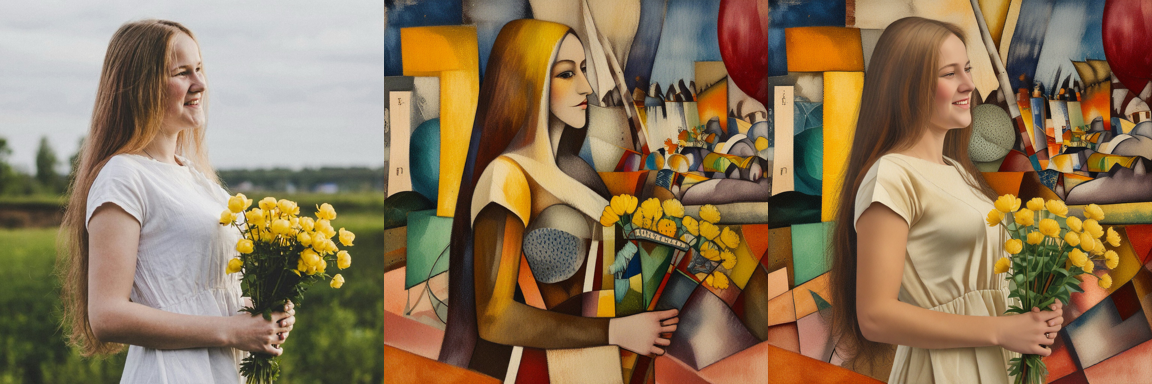

In [2]:
mask = inputs / 'masks/showcase/danila-perevoshchikov-77p2DAx00EA-unsplash-mask.jpeg'
prompt = 'a young woman holding a bouquet of yellow flowers, cubist painting, fragmented forms, Albert Gleizes inspired'
content, style = inputs / 'content/showcase/danila-1024.jpg', inputs / 'styles/gleizes_paysage_cubiste_sq.png'

uniform = lcs(prompt, content, style, content_strength=0.35, style_strength=1.0, seed=1447777030)
local = lcs(prompt, content, style,
            content_strength=Region(mask, inside=0.35, outside=0.7),
            style_strength=Region(mask, inside=1.0, outside=0.3),
            seed=1447777030)

def row(*images, size=384):
    out = Image.new('RGB', (size * len(images), size))
    for i, im in enumerate(images):
        out.paste((Image.open(im) if isinstance(im, Path) else im).convert('RGB').resize((size, size)), (i * size, 0))
    return out

row(content, uniform, local)

## A depth map on one block (Fig. 4, left)

Only InstantStyle's style block (6) is active, and its scale follows the depth map: the exemplar fades out up close.

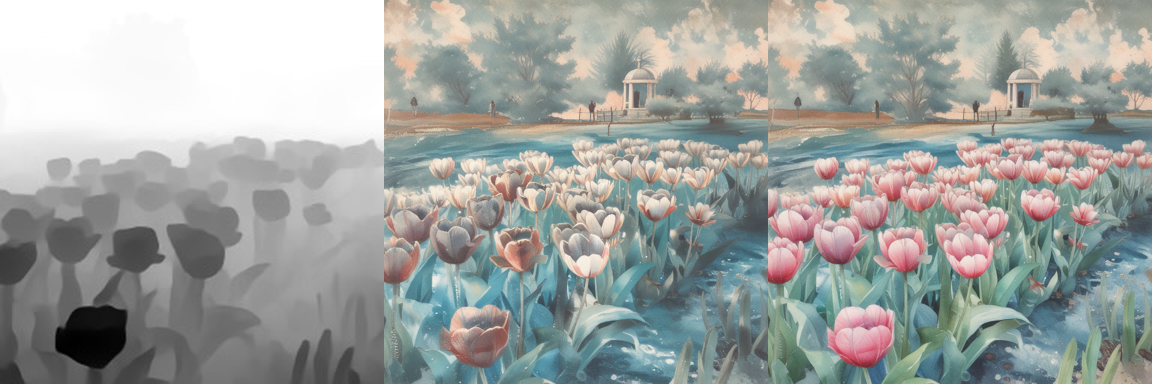

In [3]:
depth = inputs / 'masks/showcase/depth.jpeg'
args = dict(prompt='watercolor style', content_image=inputs / 'content/showcase/depth.jpg',
            style_image=inputs / 'styles/homer_sloop_nassau.png', blocks='style', seed=590662726)

row(depth, lcs(**args), lcs(**args, block_strength={6: depth}))